In [12]:
# inspecting the processed data

import numpy as np
import pandas as pd

df = pd.read_csv(r"C:\Users\cheny\Desktop\CHE1147 group project\chemixhub\datasets\drug-solubility\processed_data\processed_DrugSolubilityData.csv")

print(df.head())
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])
print("Column names:", df.columns.tolist())

    value  Temperature, K        property unit cmp_ids_solvent  \
0  1.0164          278.15  Log solubility  g/L  [125.0, 131.0]   
1  1.0601          283.15  Log solubility  g/L  [125.0, 131.0]   
2  1.1007          288.15  Log solubility  g/L  [125.0, 131.0]   
3  1.1285          293.15  Log solubility  g/L  [125.0, 131.0]   
4  1.1586          298.15  Log solubility  g/L  [125.0, 131.0]   

        cmp_mole_fractions_solvent cmp_ids_drug cmp_mole_fractions_drug  
0  [0.08378500000000001, 0.916215]          [0]                   [1.0]  
1  [0.08378500000000001, 0.916215]          [0]                   [1.0]  
2  [0.08378500000000001, 0.916215]          [0]                   [1.0]  
3  [0.08378500000000001, 0.916215]          [0]                   [1.0]  
4  [0.08378500000000001, 0.916215]          [0]                   [1.0]  
Number of rows: 27166
Number of columns: 8
Column names: ['value', 'Temperature, K', 'property', 'unit', 'cmp_ids_solvent', 'cmp_mole_fractions_solvent', 'cmp_

In [13]:
df.info()

print(df[["value", "Temperature, K"]].describe())

print(df[["property", "unit"]].value_counts(dropna=False))

<class 'pandas.DataFrame'>
RangeIndex: 27166 entries, 0 to 27165
Data columns (total 8 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   value                       27166 non-null  float64
 1   Temperature, K              27166 non-null  float64
 2   property                    27166 non-null  str    
 3   unit                        27166 non-null  str    
 4   cmp_ids_solvent             27166 non-null  str    
 5   cmp_mole_fractions_solvent  27166 non-null  str    
 6   cmp_ids_drug                27166 non-null  str    
 7   cmp_mole_fractions_drug     27166 non-null  str    
dtypes: float64(2), str(6)
memory usage: 1.7 MB
              value  Temperature, K
count  27166.000000    27166.000000
mean       0.224199      301.990418
std        1.044410       14.798865
min       -5.476500      252.550000
25%       -0.418575      288.150000
50%        0.374350      303.150000
75%        1.013475      313.1500

In [14]:
# examine missing values and duplications

print("Missing values per column:")
print(df.isna().sum())

print("Exactly duplicated rows:")
print(df.duplicated().sum())

Missing values per column:
value                         0
Temperature, K                0
property                      0
unit                          0
cmp_ids_solvent               0
cmp_mole_fractions_solvent    0
cmp_ids_drug                  0
cmp_mole_fractions_drug       0
dtype: int64
Exactly duplicated rows:
0


In [15]:
# inspect whether each row contains valid information about the drug and solvent mixture

import ast

# 1. Convert the original CSV text into Python lists
solvent_ids = df["cmp_ids_solvent"].apply(ast.literal_eval)

solvent_fractions = df["cmp_mole_fractions_solvent"].apply(
    ast.literal_eval
)

# 2. Count the items in each list
id_counts = solvent_ids.apply(len)
fraction_counts = solvent_fractions.apply(len)

# 3. Compare the counts
mismatch = id_counts != fraction_counts

# 4. Count and display affected rows
print(
    "Rows with different list lengths:",
    np.count_nonzero(mismatch)
)

print(
    df.loc[
        mismatch,
        ["cmp_ids_solvent", "cmp_mole_fractions_solvent"]
    ].head(10)
)


Rows with different list lengths: 453
     cmp_ids_solvent cmp_mole_fractions_solvent
3815  [127.0, 129.0]                      [1.0]
3816  [127.0, 129.0]                      [1.0]
3817  [127.0, 129.0]                      [1.0]
3818  [127.0, 129.0]                      [1.0]
3819  [127.0, 129.0]                      [1.0]
3820  [127.0, 129.0]                      [1.0]
3821  [127.0, 129.0]                      [1.0]
3822  [127.0, 129.0]                      [1.0]
3823  [127.0, 129.0]                      [1.0]
3824  [127.0, 129.0]                      [1.0]


In [16]:
# find the correct pairing

raw = pd.read_csv(r"C:\Users\cheny\Desktop\CHE1147 group project\chemixhub\datasets\drug-solubility\raw_data\DrugSolubilityData.csv")

print("Raw rows:", len(raw))
print("Processed rows:", len(df))

assert len(raw) == len(df), "Row counts differ"

assert (
    raw["LogS"].to_numpy() == df["value"].to_numpy()
).all(), "Measurement values differ"

assert (
    raw["Temperature, K"].to_numpy()
    == df["Temperature, K"].to_numpy()
).all(), "Temperatures differ"

print("Initial alignment checks passed")

Raw rows: 27166
Processed rows: 27166
Initial alignment checks passed


In [17]:
print("Processed record:")
print(
    df.iloc[3815][
        ["cmp_ids_solvent", "cmp_mole_fractions_solvent"]
    ]
)

print("\nRaw record:")
print(
    raw.iloc[3815][
        ["SMILES_1", "comp_1", "SMILES_2", "comp_2"]
    ]
)

Processed record:
cmp_ids_solvent               [127.0, 129.0]
cmp_mole_fractions_solvent             [1.0]
Name: 3815, dtype: object

Raw record:
SMILES_1       OC
comp_1      100.0
SMILES_2        O
comp_2        0.0
Name: 3815, dtype: object


In [18]:
compounds = pd.read_csv(r"C:\Users\cheny\Desktop\CHE1147 group project\chemixhub\datasets\drug-solubility\processed_data\compounds.csv")

print(compounds[["compound_id", "smiles"]].head())

solvent_matches = compounds["smiles"].str.strip().isin(["OC", "O"])

print(
    compounds.loc[
        solvent_matches,
        ["compound_id", "smiles"]
    ]
)

affected_compositions = raw.loc[
    mismatch,
    ["comp_1", "comp_2"]
]

print("\nAffected compositions:")
print(affected_compositions.value_counts(dropna=False))


   compound_id                                             smiles
0            0                                         Cl.N=C(N)N
1            1                           Cl.O=CC(N)C(O)C(O)C(O)CO
2            2                                   ClC=1N=C(N)C=NC1
3            3     O=N(=O)[O-].OCCC=1SC=[N+](C1C)CC2=CN=C(N=C2N)C
4            4  O=C1NC2=CC(OCCCCN3CCN(C=4C=CC=C(Cl)C4Cl)CC3)=C...
     compound_id smiles
127          127     OC
129          129      O

Affected compositions:
comp_1  comp_2
100.0   0.0       433
0.0     100.0      20
Name: count, dtype: int64


In [19]:
smiles = compounds["smiles"].str.strip()

assert not smiles.duplicated().any()
assert not compounds["compound_id"].duplicated().any()

smiles_to_id = dict(zip(smiles, compounds["compound_id"]))

print(smiles_to_id["OC"])  
print(smiles_to_id["O"])   

# repair the mismatches

repaired = df.copy()

for idx in df.index[mismatch]:

    smiles_1 = raw.at[idx, "SMILES_1"].strip()
    smiles_2 = raw.at[idx, "SMILES_2"].strip()

    id_1 = int(smiles_to_id[smiles_1])
    id_2 = int(smiles_to_id[smiles_2])

    comp_1 = float(raw.at[idx, "comp_1"])
    comp_2 = float(raw.at[idx, "comp_2"])

    assert solvent_ids.at[idx] == [id_1, id_2], (
        f"Solvent IDs disagree with raw data at index {idx}"
    )
    assert solvent_fractions.at[idx] == [1.0], (
        f"Unexpected fraction list at index {idx}"
    )
    assert [comp_1, comp_2] in ([100.0, 0.0], [0.0, 100.0]), (
        f"Unexpected raw composition at index {idx}"
    )

    if comp_1 == 100.0:
        kept_id = id_1
    else:
        kept_id = id_2

    repaired.at[idx, "cmp_ids_solvent"] = str([kept_id])

127
129


In [20]:
# check the repair 

repaired_ids = repaired["cmp_ids_solvent"].apply(ast.literal_eval)

remaining_mismatch = (
    repaired_ids.apply(len) != solvent_fractions.apply(len)
)

changed = repaired["cmp_ids_solvent"] != df["cmp_ids_solvent"]

assert changed.equals(mismatch)

assert repaired.drop(columns="cmp_ids_solvent").equals(
    df.drop(columns="cmp_ids_solvent")
)

assert len(repaired) == len(df)
assert remaining_mismatch.sum() == 0

print("Rows repaired:", changed.sum())
print("Remaining length mismatches:", remaining_mismatch.sum())
print("Rows retained:", len(repaired))

Rows repaired: 453
Remaining length mismatches: 0
Rows retained: 27166


In [21]:
# check the duplication after repair

print("Exact duplicates before repair:", df.duplicated().sum())
print("Exact duplicates after repair:", repaired.duplicated().sum())

duplicate_rows = repaired.loc[
    repaired.duplicated(keep=False)
]

print(duplicate_rows.head)

Exact duplicates before repair: 0
Exact duplicates after repair: 9
<bound method NDFrame.head of        value  Temperature, K        property unit cmp_ids_solvent  \
7905  0.8258          278.15  Log solubility  g/L           [145]   
7906  0.8851          283.15  Log solubility  g/L           [145]   
7907  0.9437          288.15  Log solubility  g/L           [145]   
7908  1.0033          293.15  Log solubility  g/L           [145]   
7909  1.0609          298.15  Log solubility  g/L           [145]   
7910  1.1096          303.15  Log solubility  g/L           [145]   
7911  1.1606          308.15  Log solubility  g/L           [145]   
7912  1.2084          313.15  Log solubility  g/L           [145]   
7913  1.2571          318.15  Log solubility  g/L           [145]   
7995  0.8258          278.15  Log solubility  g/L           [145]   
7996  0.8851          283.15  Log solubility  g/L           [145]   
7997  0.9437          288.15  Log solubility  g/L           [145]   
7998  

In [22]:
# for duplications, keeping the first occurrence
duplicate_mask = repaired.duplicated(keep="first")

removed_duplicates = repaired.loc[duplicate_mask].copy()

cleaned = repaired.drop_duplicates(keep="first").copy()

print("Rows before:", len(repaired))
print("Duplicate rows removed:", len(removed_duplicates))
print("Rows after:", len(cleaned))

assert cleaned.duplicated().sum() == 0
assert len(cleaned) + len(removed_duplicates) == len(repaired)

Rows before: 27166
Duplicate rows removed: 9
Rows after: 27157


In [23]:
# inspect whether each row contains valid information after cleaning

values = cleaned["value"]
temperatures = cleaned["Temperature, K"]

# Flag invalid measurements
invalid_value = ~np.isfinite(values)

# Flag invalid temperatures
invalid_temperature = (
    ~np.isfinite(temperatures)
    | (temperatures <= 0)
)

print("Invalid measurement values:", invalid_value.sum())
print("Invalid temperatures:", invalid_temperature.sum())

invalid_numeric = invalid_value | invalid_temperature

print(
    cleaned.loc[
        invalid_numeric,
        ["value", "Temperature, K"]
    ].head(10)
)

Invalid measurement values: 0
Invalid temperatures: 0
Empty DataFrame
Columns: [value, Temperature, K]
Index: []


In [24]:
#check if ids and solvent are valid

known_ids = set(compounds["compound_id"])

def valid_ids(items):
    if not isinstance(items, list) or len(items) == 0:
        return False

    for item in items:
        if isinstance(item, bool) or not isinstance(item, (int, float)):
            return False

        if not np.isfinite(item):
            return False

        if item < 0 or item != int(item) or item not in known_ids:
            return False

    return len(items) == len(set(items))

def valid_fractions(items):
    if not isinstance(items, list) or len(items) == 0:
        return False

    for item in items:
        if isinstance(item, bool) or not isinstance(item, (int, float)):
            return False

        if not np.isfinite(item) or not 0 <= item <= 1:
            return False

    return np.isclose(
        sum(items),
        1.0,
        rtol=0,
        atol=1e-6
    )

for kind in ["drug", "solvent"]:
    ids = cleaned[f"cmp_ids_{kind}"].apply(ast.literal_eval)
    fractions = cleaned[
        f"cmp_mole_fractions_{kind}"
    ].apply(ast.literal_eval)

    bad_ids = ~ids.apply(valid_ids)
    bad_fractions = ~fractions.apply(valid_fractions)

    print(f"\n{kind.upper()}")
    print("Invalid ID lists:", bad_ids.sum())
    print("Invalid fraction lists:", bad_fractions.sum())

    if not bad_ids.any() and not bad_fractions.any():
        bad_lengths = ids.apply(len) != fractions.apply(len)

        print("Length mismatches:", bad_lengths.sum())


DRUG
Invalid ID lists: 0
Invalid fraction lists: 0
Length mismatches: 0

SOLVENT
Invalid ID lists: 0
Invalid fraction lists: 0
Length mismatches: 0


In [25]:
# check if ID–fraction pairs in the cleaned data match the original raw data

def pairs_match(actual, expected):
    actual = sorted(actual)
    expected = sorted(expected)

    if len(actual) != len(expected):
        return False

    for (id_a, fraction_a), (id_b, fraction_b) in zip(actual, expected):
        if id_a != id_b:
            return False

        if not np.isclose(
            fraction_a, fraction_b,
            rtol=0, atol=1e-12
        ):
            return False

    return True

pair_issues = []

for idx, row in cleaned.iterrows():
    source = raw.loc[idx]

    for kind, positions in [
        ("drug", [0]),
        ("solvent", [1, 2])
    ]:
        ids = ast.literal_eval(row[f"cmp_ids_{kind}"])
        fractions = ast.literal_eval(
            row[f"cmp_mole_fractions_{kind}"]
        )

        actual = [
            (int(cid), fraction)
            for cid, fraction in zip(ids, fractions)
            if fraction != 0
        ]

        expected = []

        for position in positions:
            fraction = float(source[f"comp_{position}"]) / 100

            if fraction != 0:
                smiles = source[f"SMILES_{position}"].strip()
                cid = int(smiles_to_id[smiles])

                expected.append((cid, fraction))

        if not pairs_match(actual, expected):
            pair_issues.append((idx, kind))

print("Raw/processed pair mismatches:", len(pair_issues))
print("First examples:", pair_issues[:10])

Raw/processed pair mismatches: 0
First examples: []


In [26]:
# select subset with binary solvents of the three selected drugs: Itraconazole, Posaconazole, and Ketoconazole and save it as csv file

selected_ids = {5, 43, 86}

drug_names = {
    5: "Itraconazole",
    43: "Posaconazole",
    86: "Ketoconazole"
}

drug_lists = cleaned["cmp_ids_drug"].apply(ast.literal_eval)

def is_selected_drug(ids):
    return len(ids) == 1 and ids[0] in selected_ids

drug_mask = drug_lists.apply(is_selected_drug)

selected_drugs = cleaned.loc[drug_mask].copy()

print("Rows for the three selected drugs:", len(selected_drugs))

solvent_fraction_lists = selected_drugs[
    "cmp_mole_fractions_solvent"
].apply(ast.literal_eval)

def is_binary(fractions):
    return (
        len(fractions) == 2
        and all(fraction > 0 for fraction in fractions)
    )

binary_mask = solvent_fraction_lists.apply(is_binary)

subset = selected_drugs.loc[binary_mask].copy()

print("\nRows before binary filtering:", len(selected_drugs))
print("Rows excluded by binary filtering:", (~binary_mask).sum())
print("Final subset rows:", len(subset))

def get_single_id(ids):
    return int(ids[0])

subset_drug_ids = drug_lists.loc[subset.index].apply(get_single_id)

counts = (
    subset_drug_ids.value_counts()
    .reindex([5, 43, 86], fill_value=0)
    .rename(index=drug_names)
)

print("\nBinary observations per drug:")
print(counts)

assert subset_drug_ids.isin(selected_ids).all()
assert counts.sum() == len(subset)
assert subset.duplicated().sum() == 0

subset.to_csv("selected_drugs_binary.csv", index=False)

Rows for the three selected drugs: 684

Rows before binary filtering: 684
Rows excluded by binary filtering: 72
Final subset rows: 612

Binary observations per drug:
cmp_ids_drug
Itraconazole    360
Posaconazole    162
Ketoconazole     90
Name: count, dtype: int64


In [ ]:
# Check for the selected dataset

print("Total observations:", len(subset))

print("\nObservations per drug:")
print(subset_drug_ids.map(drug_names).value_counts(dropna=False))

review = subset.copy()

# Add readable drug names
review["drug"] = subset_drug_ids.map(drug_names)

# Create a consistent label for each solvent pair
def get_solvent_pair(text):
    ids = ast.literal_eval(text)
    return tuple(sorted(int(cid) for cid in ids))

review["solvent_pair"] = review["cmp_ids_solvent"].apply(
    get_solvent_pair
)

print("\nUnique solvent pairs per drug:")
print(review.groupby("drug")["solvent_pair"].nunique())


Total observations: 612

Observations per drug:
cmp_ids_drug
Itraconazole    360
Posaconazole    162
Ketoconazole     90
Name: count, dtype: int64

Unique solvent pairs per drug:
drug
Itraconazole    8
Ketoconazole    2
Posaconazole    2
Name: solvent_pair, dtype: int64


In [29]:
# identifying the outliers using IQR method

iqr_review = review.copy()

iqr_review["LogS_iqr_flag"] = False
iqr_review["Temperature_iqr_flag"] = False

results = []

# Group by BOTH drug and solvent pair
for (drug, pair), group in iqr_review.groupby(
    ["drug", "solvent_pair"]
):
    # Screen each numerical variable separately
    for column, label in [
        ("value", "LogS"),
        ("Temperature, K", "Temperature")
    ]:
        values = group[column]

        q1 = values.quantile(0.25)
        q3 = values.quantile(0.75)
        iqr = q3 - q1

        lower = q1 - 1.5 * iqr
        upper = q3 + 1.5 * iqr

        flags = (values < lower) | (values > upper)

        iqr_review.loc[group.index, f"{label}_iqr_flag"] = flags

        results.append({
            "Drug": drug,
            "Solvent pair": pair,
            "Variable": label,
            "Observations": len(values),
            "Q1": q1,
            "Q3": q3,
            "IQR": iqr,
            "Lower limit": lower,
            "Upper limit": upper,
            "Flagged": int(flags.sum())
        })

summary = pd.DataFrame(results)

print(summary.to_string(index=False))


flag_columns = ["LogS_iqr_flag", "Temperature_iqr_flag"]

any_flag = iqr_review[flag_columns].any(axis=1)

print("\nFlags per variable:")
print(iqr_review[flag_columns].sum())

print("\nUnique flagged observations:", any_flag.sum())

print(
    iqr_review.loc[
        any_flag,
        [
            "drug",
            "solvent_pair",
            "value",
            "Temperature, K",
            "LogS_iqr_flag",
            "Temperature_iqr_flag"
        ]
    ].to_string()
)

        Drug Solvent pair    Variable  Observations       Q1       Q3     IQR  Lower limit  Upper limit  Flagged
Itraconazole   (127, 134)        LogS            45  -0.1576   1.4038  1.5614     -2.49970      3.74590        0
Itraconazole   (127, 134) Temperature            45 293.1500 303.1500 10.0000    278.15000    318.15000        0
Itraconazole   (127, 135)        LogS            45  -0.2884   1.3369  1.6253     -2.72635      3.77485        0
Itraconazole   (127, 135) Temperature            45 293.1500 303.1500 10.0000    278.15000    318.15000        0
Itraconazole   (130, 134)        LogS            45  -0.3606   1.2749  1.6355     -2.81385      3.72815        0
Itraconazole   (130, 134) Temperature            45 293.1500 303.1500 10.0000    278.15000    318.15000        0
Itraconazole   (130, 135)        LogS            45  -0.4945   1.1717  1.6662     -2.99380      3.67100        0
Itraconazole   (130, 135) Temperature            45 293.1500 303.1500 10.0000    278.15000    31

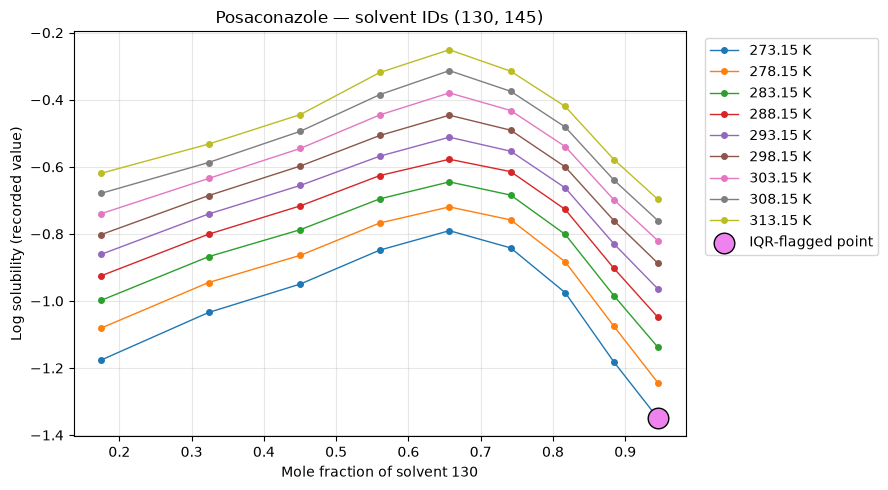

In [34]:
# deciding whether to remove or retain the outlier

import matplotlib.pyplot as plt

def get_first_solvent_fraction(row):
    ids = ast.literal_eval(row["cmp_ids_solvent"])
    fractions = ast.literal_eval(
        row["cmp_mole_fractions_solvent"]
    )

    # Keep each fraction attached to its solvent ID
    fraction_by_id = dict(zip(ids, fractions))

    first_id = row["solvent_pair"][0]

    return fraction_by_id[first_id]

review["x_first"] = review.apply(
    get_first_solvent_fraction,
    axis=1
)

plot_data = review.loc[
    (review["drug"] == "Posaconazole")
    & review["solvent_pair"].apply(lambda pair: pair == (130, 145))
].copy()

fig, ax = plt.subplots(figsize=(9, 5))

for temperature, series in plot_data.groupby("Temperature, K"):
    series = series.sort_values("x_first")

    ax.plot(
        series["x_first"],
        series["value"],
        marker="o",
        markersize=4,
        linewidth=1,
        label=f"{temperature:g} K"
    )

point = plot_data.loc[9336]

ax.scatter(
    point["x_first"],
    point["value"],
    marker="o",
    s=220,
    color="violet",
    edgecolor="black",
    zorder=10,
    label="IQR-flagged point"
)

ax.set_title("Posaconazole — solvent IDs (130, 145)")
ax.set_xlabel("Mole fraction of solvent 130")
ax.set_ylabel("Log solubility (recorded value)")
ax.grid(alpha=0.3)

ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
fig.tight_layout()
plt.show()

# retain the outlier in the dataset for further analysis as it followed the surrounding composition–solubility trend and there is insufficient evidence to classify it as an error

In [35]:
# save the final cleaned dataset, files, and image of the outlier review plot

final_data = subset.copy()

final_data.to_csv(
    "final_cleaned_binary_subset.csv",
    index=False
)

# Save the 24 grouped IQR calculations
summary.to_csv("iqr_summary.csv", index=False)

# Document the flagged observation and retention decision
flag_columns = ["LogS_iqr_flag", "Temperature_iqr_flag"]
flagged_mask = iqr_review[flag_columns].any(axis=1)

outlier_review = iqr_review.loc[flagged_mask].copy()

outlier_review["decision"] = "retain"
outlier_review["reason"] = (
    "Consistent with the surrounding composition-solubility trend; "
    "insufficient evidence to classify the observation as an error."
)

outlier_review.to_csv(
    "outlier_review.csv",
    index=True,
    index_label="original_row_index"
)

fig.savefig(
    "posaconazole_outlier_review.png",
    dpi=300,
    bbox_inches="tight"
)

print("Final dataset shape:", final_data.shape)

Final dataset shape: (612, 8)
